# Support Vector Machine (SVM)

想像桌上有兩種顏色的積木，你要畫線分開它們。很多線都能分開，但一條貼著積木的線，遇到稍微偏移的新積木就容易分错。SVM 希望在分類界線兩側留出空間，也就是 **margin（間隔）**。

真實資料通常分不乾淨：可能有量測誤差，也可能兩類本來就重疊。SVM 的 soft margin 允許部分點進入緩衝區，甚至被分錯，換取更有泛化能力的界線。

**Support Vectors（支持向量）** 是決定界線的重要訓練樣本。它們可能在間隔邊緣、間隔內，甚至位於錯誤的一側，不是只指最靠近界線的幾個點。拿掉某些遠離界線的點可能影響很小；改變支持向量則可能明顯改變模型。

在兩個特徵時，你看到的是線或曲線；三個特徵時是面；更多特徵時稱為決策超平面。不需要先學會高維幾何才能使用。

![](./assets/SVM_最大間隔與支持向量.png)

## Kernel：直線分不開時怎麼辦？

如果合格產品集中在兩個小區域，一條直線很難把它們與其他產品隔開。Kernel（核函數）提供不同的相似性比較方式，讓分類界線能呈現非線性形狀。你不需要自己產生一大串高次特徵。

| kernel | 直覺 | 何時先試 |
|---|---|---|
| `linear` | 用一條直線／平面分開 | 線性基準、高維文字特徵 |
| `rbf` | 依局部相似性形成彎曲界線 | 中小型數值資料的常見起點 |
| `poly` | 用多項式式的相似性形成曲線 | 想比較固定複雜度的曲線時 |
| `sigmoid` | 另一種非線性相似性 | 有明確實驗理由時再試 |
| `precomputed` | 直接傳入樣本相似性矩陣 | 進階用途；輸入不是普通特徵表 |

核函數不是保證高分的魔法；先建立 linear 與 RBF 基準，再用訓練資料的交叉驗證比較。

![](./assets/線性與RBF分類界線.png)


## 最先掌握的參數：C、gamma、kernel

### C：分錯訓練點時，要多嚴格？

- 小 C：較能容忍違反間隔的點，正則化較強；可能欠擬合。
- 大 C：更重視避免訓練錯誤，正則化較弱；可能對雜訊過度敏感。
- C 必須大於 0。先以 `0.1、1、10、100` 做對數尺度比較。

大 C 不保證對測試資料更好，也不代表界線一定更曲折；最終形狀還受到資料與 kernel 影響。

### gamma：RBF 的相似性影響範圍

- 小 gamma：單一樣本的影響範圍較廣，界線通常較平滑。
- 大 gamma：影響較局部，可能形成細碎的小區塊，容易記住訓練點。
- `"scale"`：依特徵數與輸入變異量設定，適合起步。
- `"auto"`：依特徵數設定。兩者不是自動調參，也不是選出的最佳 gamma。

gamma 對 `linear` 沒有作用。調整 C 時固定 gamma 只能看到部分效果；RBF 通常應一起比較兩者。

![](./assets/C與gamma的取捨.png)

## 實作：模擬產品品質分類

檔案：`data/svm_quality_control.csv`。這是教學模擬資料，不是真實工廠數據，不代表任何製程的安全規格。

| 欄位 | 意義 | 用途 |
|---|---|---|
| `temperature_c` | 製程溫度，攝氏 | Feature |
| `pressure_bar` | 製程壓力，bar | Feature |
| `passed` | 0 不合格、1 合格 | Target |

生成 800 個產品，再加入 8 筆重複紀錄。合格區域由兩個橢圓構成，32 個標籤刻意翻轉以模擬雜訊，特徵另含少量缺失值。選兩個特徵是為了直接畫出決策界線；實際專案可以使用更多特徵。


### 1. 讀取資料集


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 同時支援在專案根目錄或 SVM 資料夾執行
data_path = Path("data/svm_quality_control.csv")
df = pd.read_csv(data_path)


### 2. 探索資料 (EDA)

先不要急著丟進模型，先確認資料長什麼樣。查看標籤比例，避免只看 Accuracy 就誤以為模型很好。


,temperature_c,pressure_bar,passed
0,81.44,6.909,1
1,61.33,3.537,1
2,86.52,8.120,0
3,76.84,5.751,1
4,40.65,2.008,1


資料形狀： (808, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 808 entries, 0 to 807
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperature_c  796 non-null    float64
 1   pressure_bar   798 non-null    float64
 2   passed         808 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 19.1 KB


,temperature_c,pressure_bar,passed
count,796.000000,798.000000,808.000000
mean,64.739535,5.045336,0.241337
std,17.435979,2.329015,0.428159
min,35.070000,1.004000,0.000000
25%,49.245000,2.976500,0.000000
50%,64.725000,4.952000,0.000000
75%,80.550000,7.096750,0.000000
max,94.950000,8.995000,1.000000


temperature_c    12
pressure_bar     10
passed            0
Name: missing_count, dtype: int64

完全重複筆數： 8
類別比例：
passed
0    0.758663
1    0.241337
Name: proportion, dtype: float64


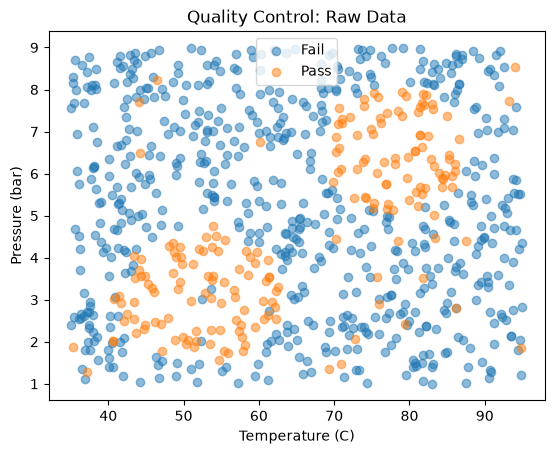

In [2]:
display(df.head())
print("資料形狀：", df.shape)
df.info()
display(df.describe())
display(df.isna().sum().rename("missing_count"))
print("完全重複筆數：", df.duplicated().sum())
print("類別比例：")
print(df["passed"].value_counts(normalize=True))

# 缺失特徵在 EDA 圖中略過；訓練時會由 Pipeline 補值
plot_df = df.dropna(subset=["temperature_c", "pressure_bar"])
for label, name in [(0, "Fail"), (1, "Pass")]:
    group = plot_df.loc[plot_df["passed"] == label]
    plt.scatter(group["temperature_c"], group["pressure_bar"], alpha=0.5, label=name)
plt.xlabel("Temperature (C)")
plt.ylabel("Pressure (bar)")
plt.title("Quality Control: Raw Data")
plt.legend()
plt.show()

### 3. 資料清理 (Data Cleaning)

特徵缺失留給 Pipeline 補值；標籤缺失不能靠平均值補成分類答案。


In [3]:
required = ["temperature_c", "pressure_bar", "passed"] # 需要的欄位
df = df[required].copy() # 保留需要的欄位

for column in required:
    df[column] = pd.to_numeric(df[column], errors="coerce") # 轉成數值，錯誤值轉為 NaN

df = df.replace([np.inf, -np.inf], np.nan) # 無限大轉為 NaN
df = df.dropna().drop_duplicates().reset_index(drop=True) # 刪除缺失值、重複資料並重設索引
df = df[df["passed"].isin([0, 1])].copy() # 只保留 0、1 兩種類別
df["passed"] = df["passed"].astype(int) # 轉為整數，例如 1.0 → 1、0.0 → 0。
display(df.info()) # 查看資料資訊

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 778 entries, 0 to 777
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperature_c  778 non-null    float64
 1   pressure_bar   778 non-null    float64
 2   passed         778 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 18.4 KB


None

### 4. 選擇 Features 與 Target


In [4]:
features = ["temperature_c", "pressure_bar"]
X = df[features]  # 保留二維表格，且不放入標籤
y = df["passed"]

### 5. 切分 Train / Test

保留 Test 20%；其餘 80% 用於訓練與交叉驗證。後續調參只使用這 80%。


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train：", X_train.shape, "Test：", X_test.shape)


Train： (622, 2) Test： (156, 2)


### 6. 建立資料前處理 Pipeline


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 定義流程時還沒有學習任何平均值、中位數或標準差
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])


### 7. 建立模型


In [7]:
from sklearn.svm import SVC

model = Pipeline([
    ("preprocessor", preprocessor),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale", class_weight=None))
])


### 8. 訓練模型


In [8]:
# fit 依序學習補值、標準化及 SVC 界線
model.fit(X_train, y_train)
print("模型訓練完成")
print("各類支持向量數量：", model.named_steps["svc"].n_support_)

模型訓練完成
各類支持向量數量： [92 86]


### 9. 使用模型預測


In [14]:
y_pred = model.predict(X_test)
y_score = model.decision_function(X_test)  # 決策分數，並非購買／合格機率
display(pd.DataFrame({"actual": y_test, "predicted": y_pred, "score": y_score}).head(10))

# # 新產品仍傳原始單位，Pipeline 會自動套用訓練好的前處理
# new_products = pd.DataFrame({"temperature_c": [52, 65, 78], "pressure_bar": [3.1, 4.5, 6.6]})
# print("新產品分類：", model.predict(new_products))


,actual,predicted,score
684,0,0,-1.269889
139,0,0,-1.526631
675,1,1,0.556504
653,0,0,-0.183814
338,0,0,-1.509606
731,1,1,2.513082
592,0,0,-3.397154
710,0,0,-1.409794
146,0,0,-1.609393
348,0,0,-2.885856


### 10. 評估模型表現

這裡定義「合格」為正類。Precision 表示放行的產品有多少真的合格；Recall 表示真正合格的產品有多少被放行。若你的任務是攔截不合格品，应改把不合格定義為正類，並重新解讀指標。


In [15]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    roc_auc_score, average_precision_score
)

print("Accuracy：", round(accuracy_score(y_test, y_pred), 4))
print("Balanced Accuracy：", round(balanced_accuracy_score(y_test, y_pred), 4))
print("ROC AUC：", round(roc_auc_score(y_test, y_score), 4))
print("Average Precision (AP)：", round(average_precision_score(y_test, y_score), 4))
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["Fail", "Pass"], zero_division=0))


Accuracy： 0.9359
Balanced Accuracy： 0.8863
ROC AUC： 0.8599
Average Precision (AP)： 0.8537
              precision    recall  f1-score   support

        Fail       0.94      0.98      0.96       118
        Pass       0.94      0.79      0.86        38

    accuracy                           0.94       156
   macro avg       0.94      0.89      0.91       156
weighted avg       0.94      0.94      0.93       156



### 11. 視覺化預測結果

#### Confusion Matrix（混淆矩陣）
觀察模型預測正確與錯誤的數量，包含 TN、FP、FN、TP。

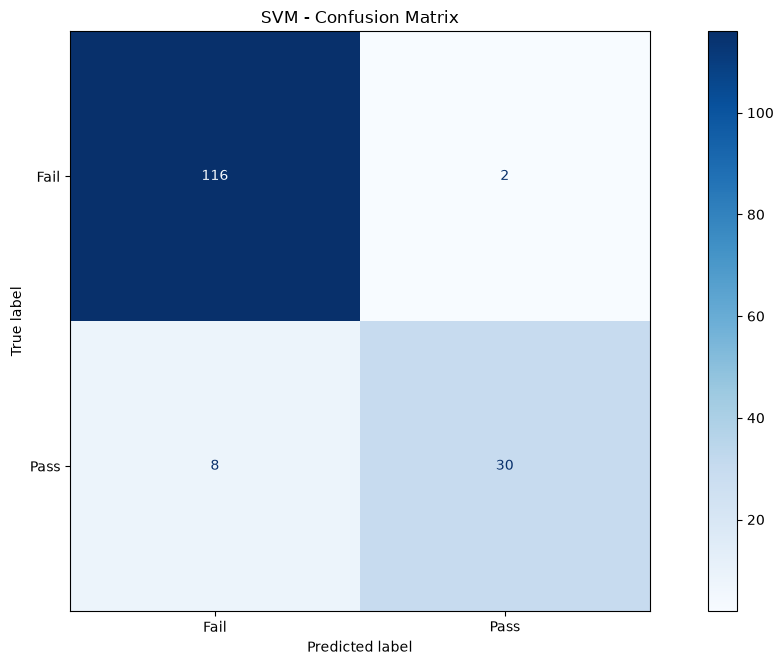

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

### 繪製 Confusion Matrix
fig, ax = plt.subplots(figsize=(12, 6.75))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, # 實際類別與預測類別
    display_labels=["Fail", "Pass"], # 類別名稱
    cmap="Blues", # 藍色色階
    values_format="d", # 顯示整數
    ax=ax
)

### 設定圖表
plt.title("SVM - Confusion Matrix")
plt.tight_layout()
plt.show()

### ROC Curve（ROC 曲線）
觀察模型在不同分類門檻下的 TPR 與 FPR，通常曲線越靠近左上角越好。

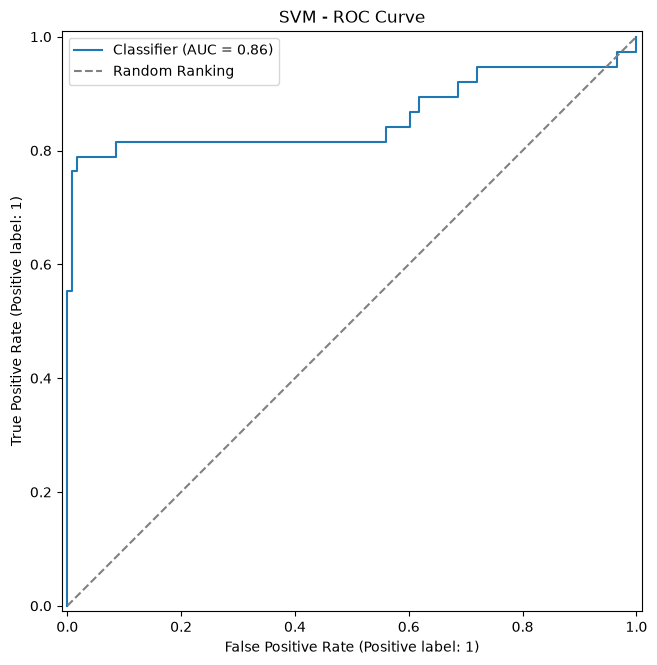

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

### 繪製 ROC Curve
fig, ax = plt.subplots(figsize=(12, 6.75))

RocCurveDisplay.from_predictions(
    y_test, y_score, # 實際類別與 SVM 決策分數
    ax=ax
)

### 繪製隨機排序參考線
ax.plot(
    [0, 1], [0, 1],
    "--", color="gray",
    label="Random Ranking"
)

### 設定圖表
ax.legend()
plt.title("SVM - ROC Curve")
plt.tight_layout()
plt.show()

#### Precision-Recall Curve（精確率－召回率曲線）
觀察 Precision 與 Recall 的取捨，特別適合分析類別不平衡的分類問題。

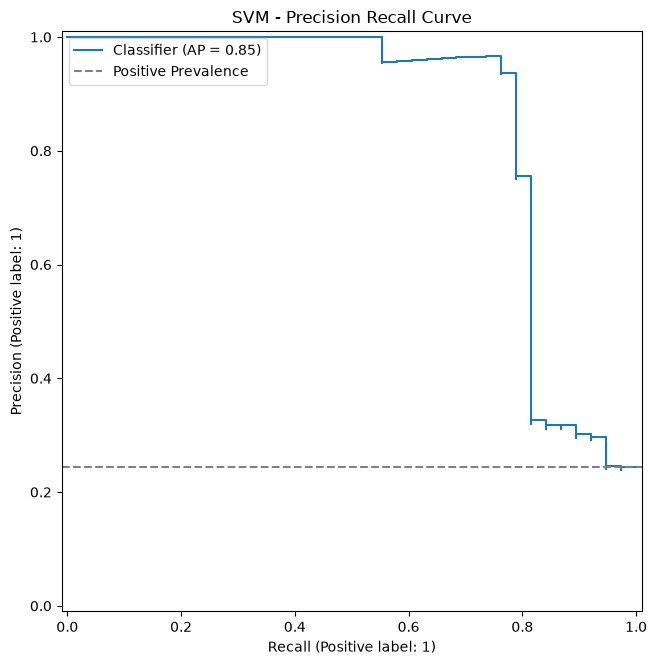

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

### 繪製 Precision-Recall Curve
fig, ax = plt.subplots(figsize=(12, 6.75))

PrecisionRecallDisplay.from_predictions(
    y_test, y_score, # 實際類別與 SVM 決策分數
    ax=ax
)

### 繪製正類別比例參考線
ax.axhline(
    y_test.mean(), # Test Data 中類別 1 的比例
    linestyle="--",
    color="gray",
    label="Positive Prevalence"
)

### 設定圖表
ax.legend()
plt.title("SVM - Precision Recall Curve")
plt.tight_layout()
plt.show()

#### SVM Decision Boundary（決策邊界）

觀察模型如何根據溫度與壓力分類，並標示 Support Vectors。

這份程式假設模型只使用 temperature_c、pressure_bar 兩個 Features，且 preprocessor 是包含 imputer、scaler 的 Pipeline。


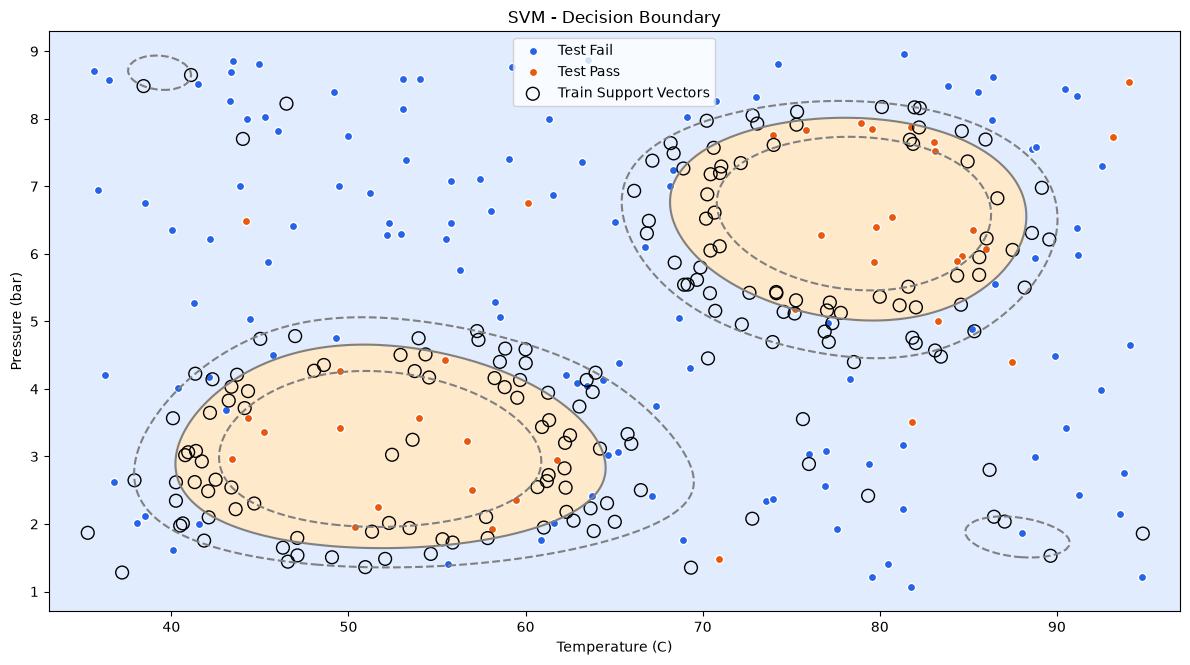

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 建立溫度與壓力的網格
t = np.linspace(X_train["temperature_c"].min()-2, X_train["temperature_c"].max()+2, 200)
p = np.linspace(X_train["pressure_bar"].min()-0.3, X_train["pressure_bar"].max()+0.3, 160)
tt, pp = np.meshgrid(t, p) # 將溫度與壓力組合成二維網格

### 建立模型預測用的 DataFrame
grid = pd.DataFrame({
    "temperature_c": tt.ravel(),
    "pressure_bar": pp.ravel()
})

### 計算網格各位置的 SVM 決策分數
scores = model.decision_function(grid).reshape(tt.shape)

### 建立圖表
plt.figure(figsize=(12, 6.75))

### 繪製分類區域
plt.contourf(
    tt, pp, (scores >= 0).astype(int),
    levels=[-0.5, 0.5, 1.5], # 分成類別 0、1
    colors=["#dae8ff", "#ffe4bf"], # 兩個類別的背景顏色
    alpha=0.8
)

### 繪製決策邊界與 ±1 等級線
plt.contour(
    tt, pp, scores,
    levels=[-1, 0, 1], # 0 為決策邊界，±1 為決策分數等級線
    colors="gray",
    linestyles=["--", "-", "--"]
)

### 取得 Pipeline 中的缺失值補值器
imputer = model.named_steps["preprocessor"].named_steps["imputer"]

### 補齊 Test Data 的缺失值
test_xy = imputer.transform(X_test)

### 繪製 Test Data 散點
for label, name, color in [(0, "Test Fail", "#2563eb"), (1, "Test Pass", "#ea580c")]:
    mask = y_test.to_numpy() == label # 篩選目前類別
    plt.scatter(
        test_xy[mask, 0], test_xy[mask, 1], # 溫度與壓力
        c=color, label=name,
        edgecolors="white", s=35
    )

### 取得 Train Data 的 Support Vectors
train_xy = imputer.transform(X_train)
support_indices = model.named_steps["svc"].support_ # 支援向量的訓練資料索引
support_xy = train_xy[support_indices] # 取得支援向量的溫度與壓力

### 標示 Support Vectors
plt.scatter(
    support_xy[:, 0], support_xy[:, 1],
    facecolors="none", edgecolors="black",
    s=85, label="Train Support Vectors"
)

### 設定圖表
plt.xlabel("Temperature (C)")
plt.ylabel("Pressure (bar)")
plt.title("SVM - Decision Boundary")
plt.legend()
plt.tight_layout()
plt.show()

| 圖上元素 | 代表意思 |
|---|---|
| 淺藍色背景 | SVM 預測為類別 0 的區域 |
| 淺橘色背景 | SVM 預測為類別 1 的區域 |
| 灰色實線 (`score=0`) | Decision Boundary，模型的分類分界線 |
| 灰色虛線 (`score=-1/+1`) | SVM 決策函數的 ±1 等級線 |
| 藍色散點 | 實際為 Fail 的 Test Data |
| 橘色散點 | 實際為 Pass 的 Test Data |
| 黑色空心圓 | Train Data 中的 Support Vectors |

## 作業：使用 SVM Classification 預測臺灣氣象測站的當日降雨累積狀態

本次作業使用政府資料開放平臺提供的「**地面測站一年觀測資料**」，並使用 **Support Vector Machine Classification (SVM 分類)** 建立模型，根據氣象測站的觀測數據，判斷當日累積降水量是否達到 1 mm。

- 資料集：[一年觀測資料－地面測站一年觀測資料](https://data.gov.tw/dataset/33029)
- 資料提供機關：中央氣象署

本次使用以下氣象觀測數據作為 Features：

```text
氣壓：測站觀測到的大氣壓力
氣溫：測站觀測到的空氣溫度
相對溼度：空氣中的水氣含量相對於飽和狀態的百分比
風速：測站觀測到的風速
```

預測：

```text
0 → 當日累積降水量 < 1 mm
1 → 當日累積降水量 >= 1 mm
```

建立以下關係：

$$
\boxed{
\text{氣象觀測數據}
\longrightarrow
\text{SVM Classification}
\longrightarrow
\text{預測當日降雨累積狀態 (0/1)}
}
$$

本次以當日累積降水量是否達到 1 mm 作為教學用的二元分類門檻，並非用來判定是否發生豪雨或其他氣象警報等級。

學生最後的 Notebook 必須按照以下順序完成：

```text
1. 讀取資料集
        ↓
2. 探索資料 (EDA)
        ↓
3. 資料清理 (Data Cleaning)
        ↓
4. 選擇 Features 與 Target
        ↓
5. 切分 Train / Test
        ↓
6. 建立資料前處理 Pipeline
        ↓
7. 建立 SVM Classification 模型
        ↓
8. 訓練模型
        ↓
9. 使用模型預測
        ↓
10. 評估模型表現
    (Accuracy / Precision / Recall / F1-score)
        ↓
11. 視覺化預測結果
    (Confusion Matrix / ROC Curve)
```

### 作業要求

1. 使用 Pandas 讀取政府開放資料，透過 `head()`、`info()`、`describe()` 觀察資料內容。
2. 檢查缺失值、重複資料、氣象觀測數值的資料型態，以及異常值或特殊缺測代碼。
3. 整理氣壓、氣溫、相對溼度、風速與當日累積降水量，確認資料欄位名稱、觀測單位及測站時間，避免不同測站或不同時間的紀錄錯誤合併。
4. 以當日累積降水量 `>= 1` 建立 `rain_status` Target，降水量缺失或無法判定的資料不可直接視為未達 1 mm。
5. 使用氣壓、氣溫、相對溼度、風速作為 Features，不可將當日累積降水量或直接由其計算的指標放入 Features。
6. 使用 `train_test_split()` 切分 Train 80%、Test 20%，並視類別數量使用 `stratify=y`。
7. 建立包含 `SimpleImputer`、`StandardScaler` 與 `SVC` 的 Pipeline，避免資料前處理造成資料洩漏。
8. 設定 `kernel="rbf"`、`C=1.0`、`gamma="scale"`、`probability=True`，訓練 SVM 分類模型。
9. 使用 `predict()` 預測類別，並使用 `predict_proba()` 取得當日累積降水量達 1 mm 類別的預測機率。
10. 計算 Accuracy、Precision、Recall、F1-score，評估模型分類表現。
11. 繪製 Confusion Matrix 與 ROC Curve，並計算 ROC AUC。

**補充說明：** 本次作業屬於依據觀測資料判斷當日累積降雨狀態的分類練習，並非預測未來是否下雨。若資料包含同一測站的連續觀測紀錄，應留意隨機切分可能使訓練集與測試集具有高度相似的時間資訊，造成模型評估過度樂觀。